# DSMarket — Clustering de productos y tiendas

**De:** Nicole, Data Science
**Para:** Joelle (Marketing Manager), Michelle (Chief Digital Officer)

Joelle pidió identificar grupos de productos que se comporten de manera similar en ventas, para poder evaluar el rendimiento de campañas de marketing por grupo en vez de producto por producto. También preguntó si el mismo enfoque sirve para agrupar **tiendas** según su perfil de demanda — útil de cara a la estrategia de expansión de la que habló Michelle. Probamos K-Means con 5, 10 y 20 grupos como pidió Joelle, para productos; para tiendas el mismo rango de K no aplica tal cual (solo hay 10 tiendas piloto) — la sección 5.1 explica por qué y qué usamos en su lugar.

Este notebook parte de las mismas fuentes y decisiones de limpieza del EDA (`01_EDA_DSMarket.ipynb`, sección 6) — no las repetimos acá.

## 1. Configuración e imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
import itertools

pd.set_option('display.max_columns', 50)
%matplotlib inline

## 2. Paleta de marca DSMarket

Misma paleta validada del EDA (sección 2 de `01_EDA_DSMarket.ipynb`) — la repetimos acá para que este notebook sea autocontenido, pero es exactamente la misma definición.

In [2]:
DSMARKET_NAVY = "#0a2a5c"
DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"
DSMARKET_GREEN = "#6a9f1f"

CITY_COLORS = {
    "Boston": DSMARKET_GREEN,
    "New York": DSMARKET_BLUE,
    "Philadelphia": DSMARKET_GOLD,
}

DSMARKET_BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
dsmarket_blues_cmap = LinearSegmentedColormap.from_list("dsmarket_blues", DSMARKET_BLUE_RAMP)

# Paleta categórica para clusters (hasta 10 grupos distinguibles) — variamos el azul de marca en tono/saturación
# en vez de usar colores por defecto de matplotlib, para mantener la identidad visual del proyecto
CLUSTER_PALETTE = [
    DSMARKET_BLUE, DSMARKET_GOLD, DSMARKET_GREEN, DSMARKET_NAVY, "#8a5fd6",
    "#d65f8a", "#5fd6c2", "#d68a5f", "#a3a3a3", "#5f8ad6",
]

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#e1e0d9",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"

## 3. Carga y limpieza de datos

Mismas decisiones que en el EDA: descartamos las filas de `item_prices.csv` sin `yearweek` (sección 6 del EDA).

Una nota práctica: las columnas de día de `item_sales.csv` son 1.913 columnas enteras (el máximo de unidades vendidas en un día es 763), así que las convertimos a `int16`. Reduce el uso de memoria a la cuarta parte y permite correr todo el notebook en una laptop sin problemas.

In [3]:
DATA_DIR = "data_dsmarket/data_dsmarket"

sales = pd.read_csv(f"{DATA_DIR}/item_sales.csv")
calendar = pd.read_csv(f"{DATA_DIR}/daily_calendar_with_events.csv")
calendar['date'] = pd.to_datetime(calendar['date'])

day_cols = [c for c in sales.columns if c.startswith('d_')]
sales[day_cols] = sales[day_cols].astype('int16')   # ver nota de memoria arriba

prices = pd.read_csv(f"{DATA_DIR}/item_prices.csv")
prices_clean = prices.dropna(subset=['yearweek'])
prices_clean = prices_clean.assign(yearweek=prices_clean['yearweek'].astype(int))
del prices

day_to_date = calendar.set_index('d')['date']
dates_of_days = day_to_date.loc[day_cols]
weekdays = dates_of_days.dt.weekday.values  # 0=lunes
months = dates_of_days.dt.month.values
is_weekend = np.isin(weekdays, [5, 6])
is_dec = months == 12

print(f"sales: {sales.shape}, prices_clean: {prices_clean.shape}, calendar: {calendar.shape}")

sales: (30490, 1920), prices_clean: (6721786, 5), calendar: (1913, 5)


## 4. Clustering de productos (pedido de Joelle)

### 4.1. Feature engineering

"Comportamiento de ventas" lo traducimos en 8 variables por producto (agregando las 10 tiendas), pensadas para capturar los ejes que le importan a una campaña de marketing — no solo cuánto vende, sino *cómo* vende:

- **`total_units`** (log): volumen total — separa productos masivos de nicho.
- **`cv_daily`**: coeficiente de variación de ventas diarias — qué tan volátil/errático es.
- **`zero_frac`**: % de días-tienda sin ninguna venta — intermitencia (rotación lenta vs. rápida).
- **`weekend_lift`**: ventas promedio fin de semana / entre semana — productos de "fin de semana" vs. rutina diaria.
- **`dec_lift`**: ventas promedio en diciembre / resto del año — sensibilidad a fin de año / regalos.
- **`event_lift`**: ventas promedio en días de evento con pico confirmado (SuperBowl, Easter, Labor Day) / días normales — qué productos se disparan en fechas señaladas. Es la variable que más directamente responde a lo que Joelle quiere accionar con campañas.
- **`trend`**: pendiente de una regresión lineal de ventas diarias en el tiempo, normalizada — creciendo, cayendo, o estable.
- **`avg_price`**: precio promedio.

Dos decisiones sobre el `event_lift`, para dejarlas explícitas:
- Como días de evento tomamos solo los que en el EDA (sección 11) mostraron un pico real: **SuperBowl, Easter y Labor Day**. Quedan afuera Thanksgiving, Christmas y NewYear porque son días de cierre o de venta muy baja: meterlos ahí mezclaría "producto que se dispara en fechas señaladas" con "día en que la tienda no vende nada".
- Como base de comparación usamos solo **días sin ningún evento**, no "todos los demás días" — si no, los días de cierre bajarían artificialmente el denominador y todos los productos parecerían sensibles a eventos.

Descartamos `n_stores_sold` (una variable candidata inicial): los 3.049 productos se venden en las 10 tiendas sin excepción, así que no aporta información para diferenciar.

In [4]:
item_day = sales.groupby('item')[day_cols].sum()
vals = item_day.values.astype(float)

# --- días de evento con pico confirmado en el EDA ---
event_series = calendar.set_index('d')['event'].loc[day_cols]
PEAK_EVENTS = ['SuperBowl', 'Easter']          # ya venían en el calendario original
labor_days = set()                              # Labor Day: primer lunes de septiembre (regla de fecha, igual que en el EDA)
for y in dates_of_days.dt.year.unique():
    d = pd.Timestamp(year=int(y), month=9, day=1)
    while d.weekday() != 0:
        d += pd.Timedelta(days=1)
    labor_days.add(d)

is_peak_event = event_series.isin(PEAK_EVENTS).values | dates_of_days.isin(labor_days).values
is_any_event = (event_series.notna().values | dates_of_days.isin(labor_days).values
                | (dates_of_days.dt.month.eq(12) & dates_of_days.dt.day.eq(25)).values)
is_normal_day = ~is_any_event
print(f"días de evento con pico: {is_peak_event.sum()} | días con algún evento: {is_any_event.sum()} | días normales: {is_normal_day.sum()}")

total_units = vals.sum(axis=1)
avg_daily = vals.mean(axis=1)
cv_daily = np.where(avg_daily > 0, vals.std(axis=1) / avg_daily, 0)
zero_frac = (vals == 0).mean(axis=1)
weekend_lift = vals[:, is_weekend].mean(axis=1) / vals[:, ~is_weekend].mean(axis=1)
dec_lift = vals[:, is_dec].mean(axis=1) / vals[:, ~is_dec].mean(axis=1)
event_lift = vals[:, is_peak_event].mean(axis=1) / vals[:, is_normal_day].mean(axis=1)

x = np.arange(vals.shape[1]); x_c = x - x.mean()
trend = (vals @ x_c) / (x_c ** 2).sum() / avg_daily

item_feat = pd.DataFrame({
    'total_units': total_units, 'cv_daily': cv_daily, 'zero_frac': zero_frac,
    'weekend_lift': weekend_lift, 'dec_lift': dec_lift, 'event_lift': event_lift, 'trend': trend,
}, index=item_day.index)
item_feat['avg_price'] = prices_clean.groupby('item')['sell_price'].mean()
item_feat['log_total_units'] = np.log1p(item_feat['total_units'])

item_meta = sales[['item', 'category', 'department']].drop_duplicates().set_index('item')
item_feat = item_feat.join(item_meta).dropna(subset=['avg_price'])

FEAT_COLS = ['log_total_units', 'cv_daily', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'trend', 'avg_price']
FEAT_COLS_SIN_EVENTO = [c for c in FEAT_COLS if c != 'event_lift']   # versión previa, para la comparación de 4.2
print(f"Productos con features completas: {len(item_feat)} de {sales['item'].nunique()}")
item_feat[FEAT_COLS].describe().round(2)

días de evento con pico: 16 | días con algún evento: 36 | días normales: 1877
Productos con features completas: 3049 de 3049


,log_total_units,cv_daily,zero_frac,weekend_lift,dec_lift,event_lift,trend,avg_price
count,3049.00,3049.00,3049.00,3049.00,3049.00,3049.00,3049.0,3049.00
mean,9.21,1.03,0.30,1.32,0.99,1.16,0.0,5.57
std,1.18,0.48,0.23,0.13,0.34,0.29,0.0,4.54
min,6.34,0.21,0.00,0.80,0.00,0.00,-0.0,0.24
25%,8.37,0.67,0.08,1.24,0.84,1.00,-0.0,2.63
50%,9.16,0.90,0.25,1.32,0.97,1.14,0.0,4.19
75%,9.97,1.29,0.48,1.40,1.11,1.29,0.0,7.19
max,13.82,3.98,0.90,1.90,7.66,3.78,0.0,39.49


Antes de clusterizar, un chequeo rápido: ¿la variable nueva aporta información propia o repite algo que ya teníamos? Si estuviera muy correlacionada con `weekend_lift` o `dec_lift` no valdría la pena sumarla.

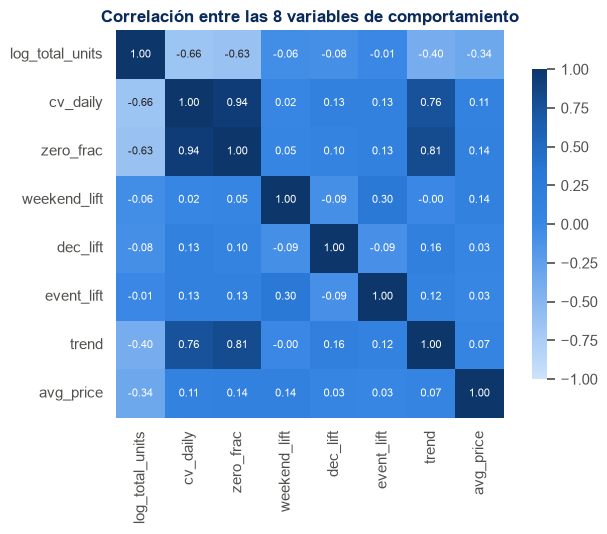

In [5]:
corr = item_feat[FEAT_COLS].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=dsmarket_blues_cmap, center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8}, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Correlación entre las 8 variables de comportamiento', color=DSMARKET_NAVY, fontweight='bold')
plt.tight_layout()
plt.show()

**Nota:** `event_lift` correlaciona apenas 0.30 con `weekend_lift` (razonable: SuperBowl y Labor Day caen en fin de semana o lunes feriado) y prácticamente nada con el resto — o sea que aporta un eje de información nuevo, no redundante. La correlación más alta de toda la matriz sigue siendo la esperable entre `cv_daily` y `zero_frac` (volatilidad e intermitencia van juntas).

### 4.2. ¿Cuántos grupos? Comparamos K=5, 10 y 20

Estandarizamos las variables (para que el precio en USD no pese más que un ratio 0-2 solo por la escala) y corremos K-Means con las 3 cantidades que pidió Joelle. Reportamos tres métricas en vez de una sola, porque cada una mira algo distinto y conviene no depender de un único número:

- **Silhouette** (de -1 a 1, más alto mejor): qué tan cerca está cada producto de su propio grupo comparado con el grupo vecino más próximo.
- **Davies-Bouldin** (más bajo mejor): relación entre dispersión interna y separación entre grupos.
- **Calinski-Harabasz** (más alto mejor): varianza entre grupos sobre varianza dentro de los grupos.

Además corremos la comparación con y sin `event_lift`, para dejar documentado qué efecto tiene la variable nueva sobre la calidad del agrupamiento.

In [6]:
resultados = []
etiquetas = {}
for nombre, cols in [('sin event_lift (7 vars)', FEAT_COLS_SIN_EVENTO), ('con event_lift (8 vars)', FEAT_COLS)]:
    X = StandardScaler().fit_transform(item_feat[cols].values)
    for k in [5, 10, 20]:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
        lab = km.labels_
        sizes = pd.Series(lab).value_counts()
        resultados.append({
            'features': nombre, 'k': k,
            'silhouette': silhouette_score(X, lab),
            'davies_bouldin': davies_bouldin_score(X, lab),
            'calinski_harabasz': calinski_harabasz_score(X, lab),
            'inercia': km.inertia_,
            'cluster_mas_chico': sizes.min(), 'cluster_mas_grande': sizes.max(),
        })
        etiquetas[(nombre, k)] = lab

X_items = StandardScaler().fit_transform(item_feat[FEAT_COLS].values)   # el que usamos de acá en adelante
for k in [5, 10, 20]:
    item_feat[f'cluster_k{k}'] = etiquetas[('con event_lift (8 vars)', k)]

pd.DataFrame(resultados).set_index(['features', 'k']).round(3)

silhouette  davies_bouldin  calinski_harabasz  \
features                k                                                   
sin event_lift (7 vars) 5        0.183           1.530            796.934   
                        10       0.171           1.458            582.568   
                        20       0.150           1.353            434.280   
con event_lift (8 vars) 5        0.158           1.714            640.518   
                        10       0.144           1.611            464.406   
                        20       0.130           1.454            336.197   

                              inercia  cluster_mas_chico  cluster_mas_grande  
features                k                                                     
sin event_lift (7 vars) 5   10425.369                202                 881  
                        10   7831.498                 44                 556  
                        20   5731.035                  1                 326  
con event_lift (8 vars) 5   13244.449                189                 948  
                        10  10268.854                 64                 580  
                        20   7845.976                  1                 402

In [7]:
# ¿Cuánto cambia realmente la segmentación al sumar event_lift? (K=5)
ari = adjusted_rand_score(etiquetas[('sin event_lift (7 vars)', 5)], etiquetas[('con event_lift (8 vars)', 5)])
print(f"Adjusted Rand Index entre la segmentación de 7 y la de 8 variables (K=5): {ari:.3f}")
pd.crosstab(pd.Series(etiquetas[('sin event_lift (7 vars)', 5)], name='K=5 sin event_lift'),
            pd.Series(etiquetas[('con event_lift (8 vars)', 5)], name='K=5 con event_lift'))

Adjusted Rand Index entre la segmentación de 7 y la de 8 variables (K=5): 0.701


K=5 con event_lift,0,1,2,3,4
K=5 sin event_lift,,,,,
0,0,837,0,44,0
1,1,0,454,1,101
2,1,42,26,84,442
3,3,67,2,724,18
4,184,2,2,6,8


**Hallazgo — K=5 es el mejor de los tres que pidió Joelle, y las tres métricas coinciden en el orden:**

Con las 8 variables, K=5 da **silhouette 0.158**, **Davies-Bouldin 1.714** y **Calinski-Harabasz 640.5**; K=10 y K=20 empeoran las tres (silhouette 0.144 y 0.130). El silhouette es moderado en términos absolutos, pero eso es lo esperable en datos de comportamiento de venta: los productos no forman islas separadas sino un continuo, y lo que buscamos es una partición útil, no grupos geométricamente perfectos. K=20 además deja un cluster de **un solo producto** — un outlier tan extremo que K-Means lo aísla; lo investigamos en la sección 4.7 porque resultó ser un hallazgo de negocio en sí mismo.

**Sobre `event_lift`, siendo transparentes con el trade-off:** agregar la variable *empeora levemente* las tres métricas (silhouette baja de 0.183 a 0.158). Parte de esa caída es mecánica — sumar una dimensión casi siempre baja el silhouette, porque las distancias se estiran en un espacio más grande — y no significa que la segmentación sea peor para el negocio. La estructura de fondo se mantiene: el **ARI entre ambas versiones es 0.70**, es decir que los 5 arquetipos son esencialmente los mismos, apenas con las fronteras corridas. Y a cambio ganamos un eje que Joelle puede accionar directamente: en la segmentación fina de K=10 (sección 4.6) aparece un grupo de productos que **duplica sus ventas en días de evento**, que sin esta variable quedaba disuelto entre los demás.

**Decisión:** usamos las 8 variables (con `event_lift`) como segmentación principal, con K=5 para la lectura estratégica y K=10 documentado para campañas puntuales. Dejamos la comparación de arriba en el notebook para que la decisión quede justificada y no parezca arbitraria.

### 4.3. ¿K-Means o algo más? Comparación con Gaussian Mixture

K-Means asume grupos aproximadamente esféricos y del mismo tamaño; nuestras variables son heterogéneas (log-volumen, ratios, precio), así que vale preguntarse si un modelo más flexible agrupa mejor. Probamos **Gaussian Mixture Models (GMM)**, que permite grupos elípticos de distinto tamaño y orientación, con las tres formas de matriz de covarianza. Comparamos las mismas tres métricas más el **ARI** contra K-Means (cuánto se parecen las dos particiones).

In [8]:
comparacion = []
km5 = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_items)
lab_km = km5.labels_
sizes_km = pd.Series(lab_km).value_counts()
comparacion.append({'modelo': 'K-Means', 'silhouette': silhouette_score(X_items, lab_km),
                    'davies_bouldin': davies_bouldin_score(X_items, lab_km),
                    'calinski_harabasz': calinski_harabasz_score(X_items, lab_km),
                    'grupo_mas_chico': sizes_km.min(), 'ARI_vs_KMeans': 1.0})

for cov in ['full', 'diag', 'spherical']:
    gm = GaussianMixture(n_components=5, covariance_type=cov, random_state=42, n_init=5).fit(X_items)
    lab = gm.predict(X_items)
    sizes = pd.Series(lab).value_counts()
    comparacion.append({'modelo': f'GMM ({cov})', 'silhouette': silhouette_score(X_items, lab),
                        'davies_bouldin': davies_bouldin_score(X_items, lab),
                        'calinski_harabasz': calinski_harabasz_score(X_items, lab),
                        'grupo_mas_chico': sizes.min(), 'ARI_vs_KMeans': adjusted_rand_score(lab_km, lab)})
    item_feat[f'gmm_{cov}'] = lab

pd.DataFrame(comparacion).set_index('modelo').round(3)

,silhouette,davies_bouldin,calinski_harabasz,grupo_mas_chico,ARI_vs_KMeans
modelo,,,,,
K-Means,0.158,1.714,640.518,189,1.000
GMM (full),0.069,2.885,360.544,352,0.196
GMM (diag),0.105,2.368,485.919,471,0.318
GMM (spherical),0.139,2.624,484.206,261,0.443


In [9]:
# ¿Cómo quedan los perfiles del GMM? (para ver si son interpretables o quedan difusos)
perfil_gmm = item_feat.groupby('gmm_full')[['total_units', 'cv_daily', 'zero_frac',
                                            'weekend_lift', 'dec_lift', 'event_lift', 'avg_price']].mean()
perfil_gmm.insert(0, 'n_productos', item_feat.groupby('gmm_full').size())
perfil_gmm.round(2)

,n_productos,total_units,cv_daily,zero_frac,weekend_lift,dec_lift,event_lift,avg_price
gmm_full,,,,,,,,
0,772,8655.86,0.90,0.24,1.33,0.99,1.14,8.63
1,723,27748.22,0.96,0.31,1.31,0.94,1.15,3.03
2,706,41593.56,0.57,0.04,1.32,0.91,1.12,3.64
3,352,20636.26,1.48,0.44,1.32,1.13,1.31,5.10
4,496,4681.66,1.66,0.62,1.31,1.06,1.17,7.57


**Hallazgo — K-Means gana claramente, y ahora lo podemos justificar con evidencia en vez de con costumbre:**

Las tres variantes de GMM quedan por debajo de K-Means en las tres métricas. La mejor de ellas (esférica) llega a silhouette 0.139 contra 0.158 de K-Means, y la más flexible (`full`) es la peor de todas (0.069, con Davies-Bouldin 2.885 contra 1.714). El ARI contra K-Means va de 0.20 a 0.44: no es que GMM encuentre lo mismo de otra forma, encuentra particiones bastante distintas.

Y más importante que las métricas: **los perfiles del GMM son menos accionables**. Al mirar la tabla de arriba, los cinco grupos del GMM se diferencian sobre todo por volumen (de 4.700 a 41.600 unidades promedio) pero comparten casi el mismo `weekend_lift` (1.31-1.33) y precios más mezclados — desaparece el grupo premium nítido y el grupo de fin de semana que sí separa K-Means. Para el objetivo de Joelle (agrupar por *comportamiento*, no por tamaño) eso es un retroceso.

**Decisión:** seguimos con K-Means. La comparación queda documentada para la memoria y para la defensa, donde es probable que pregunten por qué elegimos este algoritmo.

### 4.4. Visualización de los 5 grupos (PCA a 2 componentes)

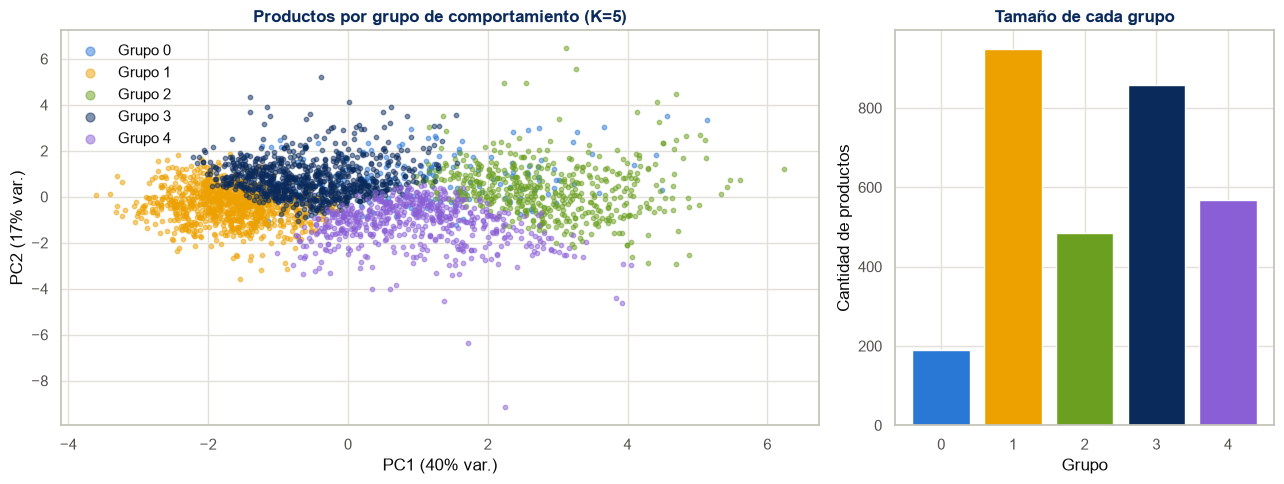

Varianza explicada por PC1+PC2: 57% (el resto de las 8 dimensiones no entra en este gráfico 2D)


In [10]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_items)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [2, 1]})

ax = axes[0]
for cl in sorted(item_feat['cluster_k5'].unique()):
    mask = item_feat['cluster_k5'] == cl
    ax.scatter(coords[mask, 0], coords[mask, 1], s=10, alpha=0.5, color=CLUSTER_PALETTE[cl], label=f'Grupo {cl}')
ax.set_xlabel(f'PC1 ({var_exp[0]:.0%} var.)')
ax.set_ylabel(f'PC2 ({var_exp[1]:.0%} var.)')
ax.set_title('Productos por grupo de comportamiento (K=5)', color=DSMARKET_NAVY, fontweight='bold')
ax.legend(frameon=False, markerscale=2, loc='best')

ax2 = axes[1]
sizes = item_feat['cluster_k5'].value_counts().sort_index()
ax2.bar(sizes.index.astype(str), sizes.values, color=[CLUSTER_PALETTE[i] for i in sizes.index])
ax2.set_xlabel('Grupo')
ax2.set_ylabel('Cantidad de productos')
ax2.set_title('Tamaño de cada grupo', color=DSMARKET_NAVY, fontweight='bold')
plt.tight_layout()
plt.show()
print(f"Varianza explicada por PC1+PC2: {var_exp.sum():.0%} (el resto de las 8 dimensiones no entra en este gráfico 2D)")

### 4.5. Perfil de cada grupo — ¿qué significa cada uno para Joelle?

En la tabla, `trend` aparece convertido a **% anual aproximado** (`trend_anual_pct`) para que se pueda leer: es la pendiente de la regresión de ventas diarias, relativa al nivel medio del producto y llevada a un año. Es un indicador grueso de dirección — sirve para comparar grupos entre sí, no como proyección de crecimiento.

In [11]:
PROFILE_COLS = ['total_units', 'cv_daily', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'trend', 'avg_price']

def perfil(col_cluster):
    """Perfil promedio de cada grupo. `trend` se expresa como % anual aproximado para que se lea."""
    g = item_feat.groupby(col_cluster)
    p = g[PROFILE_COLS].mean()
    p.insert(0, 'n_productos', g.size())
    p.insert(1, 'pct', (g.size() / len(item_feat) * 100).round(1))
    p['trend_anual_pct'] = p.pop('trend') * 365 * 100
    return p.round(2)

perfil('cluster_k5')

,n_productos,pct,total_units,cv_daily,zero_frac,weekend_lift,dec_lift,event_lift,avg_price,trend_anual_pct
cluster_k5,,,,,,,,,,
0,189,6.2,6831.44,1.10,0.37,1.36,0.98,1.15,18.08,22.62
1,948,31.1,48443.43,0.64,0.09,1.27,0.95,1.10,3.53,-0.09
2,484,15.9,4635.49,1.79,0.66,1.36,1.02,1.36,5.36,66.75
3,859,28.2,12976.49,0.85,0.21,1.41,0.91,1.25,5.73,4.43
4,569,18.7,8944.65,1.26,0.44,1.23,1.16,0.97,4.72,35.72


In [12]:
cat_mix = pd.crosstab(item_feat['cluster_k5'], item_feat['category'], normalize='index') * 100
cat_mix.round(1)

category,ACCESORIES,HOME_&_GARDEN,SUPERMARKET
cluster_k5,,,
0,49.7,41.3,9.0
1,11.6,20.4,68.0
2,18.8,39.0,42.1
3,13.5,50.1,36.4
4,27.1,27.6,45.3


**Hallazgo — 5 arquetipos de comportamiento, con nombre de trabajo para usar con Joelle:**

- **Grupo 1 — "Núcleo estable" (948 productos, 31%):** el volumen más alto por lejos (48.400 unidades promedio contra 4.600-13.000 del resto), con la volatilidad y la intermitencia más bajas (`cv` 0.64, apenas 9% de días-tienda sin venta). Son los productos que se venden todos los días, sin sobresaltos: 68% SUPERMARKET, precio bajo (USD 3.53). Es el motor del negocio — no necesitan campaña para vender, pero son la base contra la que se mide cualquier promoción.
- **Grupo 3 — "Fin de semana / hogar" (859, 28%):** el `weekend_lift` más alto (+41% el fin de semana respecto de entre semana) y 50% HOME_&_GARDEN — consistente con proyectos de fin de semana en casa. Es además el grupo que más *baja* en diciembre (`dec_lift` 0.91). Candidato natural para campañas de viernes y sábado.
- **Grupo 4 — "Fin de año, ajeno a las fechas señaladas" (569, 19%):** el `dec_lift` más alto (1.16, +16% en diciembre) y, al mismo tiempo, el único grupo con `event_lift` por debajo de 1 (0.97). Se mueve por la temporada de fin de año, no por eventos sueltos del calendario. También tiene el `weekend_lift` más bajo (1.23): es compra de rutina, no de fin de semana.
- **Grupo 2 — "Cola larga sensible a eventos" (484, 16%):** el volumen más bajo (4.600 unidades), la mayor volatilidad e intermitencia (66% de días-tienda sin ninguna venta) y **el `event_lift` más alto de los cinco (1.36)**. Es también el grupo con la tendencia de crecimiento más marcada del conjunto: rotación lenta pero en alza, y con respuesta fuerte a fechas puntuales. Vale la pena mirarlo de cerca, puede haber productos emergentes ahí adentro.
- **Grupo 0 — "Premium / accesorios" (189, 6%):** precio promedio USD 18.08 contra 3.53-5.73 de los otros cuatro (3 a 5 veces más caro) y la mayor concentración de ACCESORIES (50%). Volumen bajo, típico de ticket alto.

**Para Joelle:** si el objetivo es medir el impacto de una campaña, comparar contra el grupo (y no contra el producto individual) da una base mucho más justa — cada grupo ya trae incorporado su propio nivel "normal" de volatilidad y de estacionalidad. Y el eje nuevo ya separa dos públicos que antes se confundían: el Grupo 2 responde a **fechas señaladas** y el Grupo 4 a la **temporada de diciembre**. No son la misma campaña ni el mismo calendario.

### 4.6. Segmentación fina: interpretación de K=10

Joelle pidió probar también 10 y 20 grupos. Veinte es inmanejable para armar campañas (y deja grupos de un puñado de productos), pero **K=10 sí tiene una lectura útil**: no reemplaza a K=5, lo *subdivide*. Los cinco arquetipos siguen ahí, y adentro aparecen micro-segmentos que a nivel K=5 quedan promediados y se pierden — justo los que sirven para una campaña concreta con fecha en el calendario.

In [13]:
perfil('cluster_k10').sort_values('total_units', ascending=False)

,n_productos,pct,total_units,cv_daily,zero_frac,weekend_lift,dec_lift,event_lift,avg_price,trend_anual_pct
cluster_k10,,,,,,,,,,
3,524,17.2,71326.50,0.59,0.08,1.28,0.93,1.14,2.66,-2.10
6,347,11.4,20418.87,1.12,0.42,1.32,0.97,1.19,3.34,44.80
1,580,19.0,16244.58,0.69,0.11,1.41,0.97,1.23,5.77,-1.26
8,501,16.4,12078.22,0.80,0.16,1.21,0.98,0.99,5.46,2.83
9,64,2.1,10763.19,1.44,0.42,1.30,2.29,1.02,4.78,27.27
4,141,4.6,6963.83,1.11,0.38,1.35,1.03,1.15,19.80,24.86
0,285,9.3,5431.71,1.17,0.39,1.42,0.76,1.30,6.66,9.45
7,93,3.1,4270.06,1.90,0.66,1.35,0.95,1.99,4.78,64.88
5,233,7.6,4254.75,1.53,0.56,1.18,1.08,0.89,5.28,48.91


In [14]:
cat_mix10 = pd.crosstab(item_feat['cluster_k10'], item_feat['category'], normalize='index') * 100
cat_mix10.round(1)

category,ACCESORIES,HOME_&_GARDEN,SUPERMARKET
cluster_k10,,,
0,18.6,55.1,26.3
1,14.0,49.5,36.6
2,16.7,45.6,37.7
3,9.0,15.8,75.2
4,53.9,39.0,7.1
5,29.2,30.0,40.8
6,9.2,30.0,60.8
7,19.4,22.6,58.1
8,22.8,26.5,50.7


In [15]:
# ¿Cómo se reparten los 5 arquetipos dentro de los 10 grupos?
pd.crosstab(item_feat['cluster_k5'], item_feat['cluster_k10'])

cluster_k10,0,1,2,3,4,5,6,7,8,9
cluster_k5,,,,,,,,,,
0,24,3,4,0,140,0,2,0,14,2
1,0,113,0,523,0,0,32,0,276,4
2,34,0,275,0,0,29,42,91,0,13
3,193,464,0,1,0,0,94,2,102,3
4,34,0,2,0,1,204,177,0,109,42


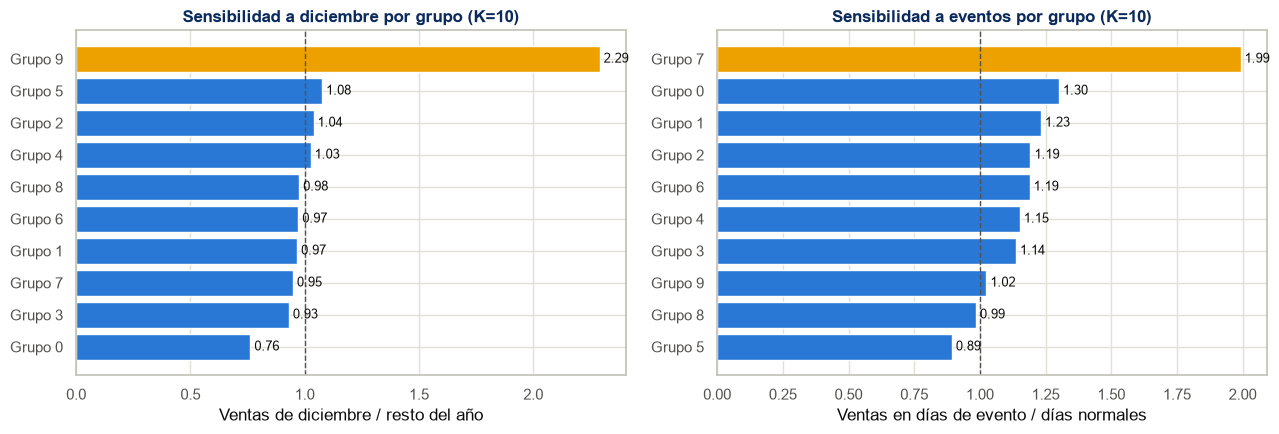

In [16]:
# Los dos micro-segmentos que solo aparecen con K=10, vistos de cerca
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, (col, titulo, xlabel) in zip(axes, [
        ('dec_lift', 'Sensibilidad a diciembre por grupo (K=10)', 'Ventas de diciembre / resto del año'),
        ('event_lift', 'Sensibilidad a eventos por grupo (K=10)', 'Ventas en días de evento / días normales')]):
    serie = item_feat.groupby('cluster_k10')[col].mean().sort_values()
    colores = [DSMARKET_GOLD if v == serie.max() else DSMARKET_BLUE for v in serie.values]
    ax.barh([f'Grupo {i}' for i in serie.index], serie.values, color=colores)
    ax.axvline(1, color='#52514e', linestyle='--', linewidth=1)
    ax.set_title(titulo, color=DSMARKET_NAVY, fontweight='bold')
    ax.set_xlabel(xlabel)
    for i, v in enumerate(serie.values):
        ax.text(v, i, f' {v:.2f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Hallazgo — K=10 revela dos micro-segmentos accionables que K=5 disuelve:**

- **Grupo 9 — "Temporada de fin de año" (64 productos, 2%):** `dec_lift` **2.29**, es decir que venden 2,3 veces más en diciembre que en el resto del año — contra el 1.16 del grupo "fin de año" de K=5. Son 45% ACCESORIES y 41% SUPERMARKET: regalo y mesa festiva. A nivel K=5 estos 64 productos quedaban diluidos entre 569 y su señal se perdía en el promedio.
- **Grupo 7 — "Fechas señaladas" (93 productos, 3%):** `event_lift` **1.99** — literalmente **duplican sus ventas** los días de SuperBowl, Easter y Labor Day, y en cambio diciembre les es indiferente (`dec_lift` 0.95). 58% SUPERMARKET. Este grupo directamente no existe sin la variable `event_lift`: es el argumento más concreto a favor de haberla agregado, más allá de lo que digan las métricas internas.

Los otros ocho grupos son subdivisiones razonables de los cinco arquetipos: el núcleo se parte en un bloque masivo (grupo 3, 71.300 unidades promedio, 75% SUPERMARKET) y uno de volumen medio (grupo 6); el premium se aísla más puro (grupo 4, precio promedio USD 19.80, 54% ACCESORIES); y la cola larga se separa en una versión clásica (grupo 2) y otra insensible a todo (grupo 5, con el `event_lift` y el `weekend_lift` más bajos del conjunto: 0.89 y 1.18). Aparece además un grupo 0 (285 productos) que combina el `weekend_lift` más alto (1.42) con el `dec_lift` más bajo (0.76): hogar de fin de semana que se apaga en diciembre.

**Recomendación para Joelle:** usar **K=5 como lenguaje común** para hablar del catálogo y medir el rendimiento de campañas, y **K=10 para armar el calendario de campañas** — los grupos 9 y 7 son dos audiencias con fecha propia (la temporada de diciembre y las fechas señaladas del año) que merecen su propia acción comercial y su propia previsión de stock.

### 4.7. El producto que K-Means aísla solo: un caso de estacionalidad extrema

En la sección 4.2 vimos que con K=20 aparece un cluster de **un solo producto**. En vez de descartarlo como ruido, lo miramos de cerca: cuando un algoritmo decide que algo no se parece a nada, muchas veces está señalando el caso más interesante del dataset.

In [17]:
outlier_id = item_feat.loc[item_feat['cluster_k20'].map(item_feat['cluster_k20'].value_counts()) == 1].index[0]
print(f"Producto aislado por K-Means en K=20: {outlier_id}")
print()
print(item_feat.loc[outlier_id, PROFILE_COLS + ['category', 'department']])
print()
print("Percentil de este producto dentro de los 3.049, variable por variable:")
for col in PROFILE_COLS:
    pct = (item_feat[col] < item_feat.loc[outlier_id, col]).mean()
    print(f"  {col:16s} valor={item_feat.loc[outlier_id, col]:>10.2f}   percentil={pct:.1%}")

Producto aislado por K-Means en K=20: SUPERMARKET_3_069

total_units           35502.0
cv_daily             2.686841
zero_frac            0.034501
weekend_lift         1.104176
dec_lift             7.658697
event_lift           0.779235
trend                0.000065
avg_price            3.563558
category          SUPERMARKET
department      SUPERMARKET_3
Name: SUPERMARKET_3_069, dtype: object

Percentil de este producto dentro de los 3.049, variable por variable:
  total_units      valor=  35502.00   percentil=86.1%
  cv_daily         valor=      2.69   percentil=99.7%
  zero_frac        valor=      0.03   percentil=14.4%
  weekend_lift     valor=      1.10   percentil=4.3%
  dec_lift         valor=      7.66   percentil=100.0%
  event_lift       valor=      0.78   percentil=5.7%
  trend            valor=      0.00   percentil=38.8%
  avg_price        valor=      3.56   percentil=40.8%


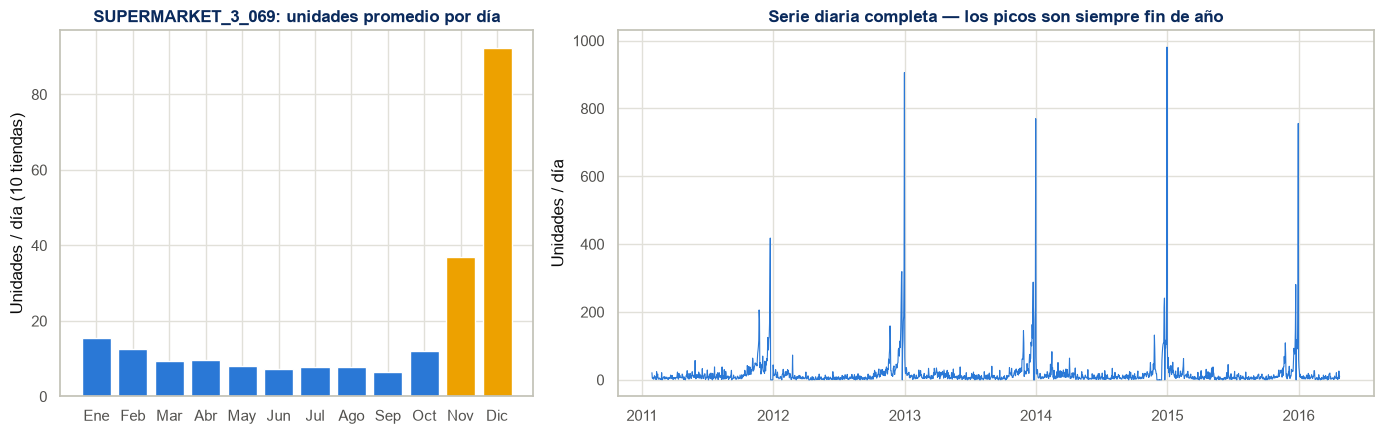

Los 6 días de mayor venta de este producto en los 5 años:
2014-12-31    981
2012-12-31    906
2013-12-31    770
2015-12-31    756
2011-12-24    418
2012-12-30    333


In [18]:
serie_outlier = pd.Series(item_day.loc[outlier_id].values, index=dates_of_days.values)
por_mes = serie_outlier.groupby(serie_outlier.index.month).mean()
MESES = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})

colores = [DSMARKET_GOLD if m in (11, 12) else DSMARKET_BLUE for m in por_mes.index]
axes[0].bar([MESES[m - 1] for m in por_mes.index], por_mes.values, color=colores)
axes[0].set_title(f'{outlier_id}: unidades promedio por día', color=DSMARKET_NAVY, fontweight='bold')
axes[0].set_ylabel('Unidades / día (10 tiendas)')

axes[1].plot(serie_outlier.index, serie_outlier.values, color=DSMARKET_BLUE, linewidth=0.8)
axes[1].set_title('Serie diaria completa — los picos son siempre fin de año',
                  color=DSMARKET_NAVY, fontweight='bold')
axes[1].set_ylabel('Unidades / día')
plt.tight_layout()
plt.show()

print("Los 6 días de mayor venta de este producto en los 5 años:")
print(serie_outlier.sort_values(ascending=False).head(6).to_string())

**Hallazgo — `SUPERMARKET_3_069` es un producto de temporada de fin de año, y merece tratamiento propio:**

Los números lo dicen solos: es el producto con el `dec_lift` **más alto de los 3.049** (7.66: vende 7,6 veces más en diciembre que en el resto del año) y está en el percentil 99.7 de volatilidad — pero al mismo tiempo casi no tiene días sin venta (percentil 14 de intermitencia) y vende bastante (percentil 86 de volumen). O sea: **no es un producto errático, es un producto con una temporada.** Vende entre 7 y 15 unidades por día durante casi todo el año, sube a 37 en noviembre y llega a **92 unidades por día en diciembre**.

El detalle que cierra la historia: sus mejores días en cinco años son **cuatro 31 de diciembre** (981, 906, 770 y 756 unidades), más un 24 y un 30 de diciembre. Es un producto de Nochevieja. Su `event_lift` es 0.78 (percentil 6): no le importan el SuperBowl ni Easter — le importa una sola semana del año, todos los años.

**Por qué esto importa más allá de la curiosidad estadística:**
1. **Para Joelle:** es el caso testigo del Grupo 9. Un producto así justifica por sí solo una campaña de fin de año con nombre propio, y sirve para explicarle a cualquiera qué significa el segmento.
2. **Para la Tarea 3 (forecasting):** un producto así rompe cualquier modelo que no incluya variables de calendario. Un promedio móvil lo va a subestimar sistemáticamente todo diciembre y sobreestimar todo enero — es un buen caso de prueba para comparar modelos.
3. **Para la Tarea 4 (abastecimiento):** es exactamente el tipo de producto donde el stock de seguridad no puede calcularse sobre la demanda media anual; necesita una política estacional propia o va a haber quiebre de stock el 31 de diciembre.

## 5. Clustering de tiendas (Joelle: ¿qué tiendas tienen perfiles de demanda similares?)

### 5.1. Nota metodológica — por qué acá NO usamos K=5/10/20

El pedido original de Joelle probaba 5, 10 y 20 grupos pensando en productos (3.049 casos). Con solo **10 tiendas**, ese mismo rango no tiene sentido: K=10 pondría cada tienda en su propio grupo (no agrupa nada) y K=20 ni siquiera es calculable (no puede haber más grupos que puntos). Dejamos esto marcado como una decisión técnica, no como que nos salteamos el pedido: para tiendas usamos **clustering jerárquico (Ward)**, más apropiado con tan pocos casos porque el dendrograma se puede leer directamente sin tener que adivinar K de antemano, y evaluamos K=2, 3 y 4. Comparamos además contra K-Means para confirmar que la elección de algoritmo no cambia el resultado.

### 5.2. Feature engineering (perfil de demanda por tienda)

El perfil de cada tienda combina cuatro cosas: **cuánto vende** (`log_avg_daily`), **con qué regularidad** (`cv_daily`), **con qué estacionalidad** (`weekend_lift`, `dec_lift`), **qué vende** (el mix de los 7 departamentos) y **a qué nivel de precio** (índice de precio relativo, sección 10.1 del EDA).

Sobre el índice de precio calculamos **dos variantes**, porque la elección no es neutral:
- **Simple:** promedia el precio relativo de todos los productos por igual. Un producto de SUPERMARKET que vende miles de unidades pesa lo mismo que un accesorio que casi no rota.
- **Ponderado por volumen:** pondera cada producto por las unidades que esa tienda efectivamente vendió. Refleja mejor el precio que paga un cliente real en esa tienda.

Usamos la simple como variante principal (es la del EDA) y en la sección 5.7 comprobamos si la conclusión cambia con la ponderada.

In [19]:
store_day = sales.groupby('store_code')[day_cols].sum()
vals_s = store_day.values.astype(float)
avg_daily_s = vals_s.mean(axis=1)

store_feat = pd.DataFrame({
    'avg_daily': avg_daily_s,
    'cv_daily': vals_s.std(axis=1) / avg_daily_s,
    'weekend_lift': vals_s[:, is_weekend].mean(axis=1) / vals_s[:, ~is_weekend].mean(axis=1),
    'dec_lift': vals_s[:, is_dec].mean(axis=1) / vals_s[:, ~is_dec].mean(axis=1),
}, index=store_day.index)
store_feat['log_avg_daily'] = np.log1p(store_feat['avg_daily'])

# Mix de departamento por tienda -> el corazón del "perfil de demanda"
sales_tot = sales[['store_code', 'department']].copy()
sales_tot['total_units'] = sales[day_cols].sum(axis=1)
dept_totals = sales_tot.groupby(['store_code', 'department'])['total_units'].sum().unstack('department').fillna(0)
dept_mix = dept_totals.div(dept_totals.sum(axis=1), axis=0) * 100
DEPT_COLS = dept_mix.columns.tolist()
store_feat = store_feat.join(dept_mix)

# Índice de precio por tienda: variante simple (la del EDA) y variante ponderada por volumen
avg_price_by_item_store = prices_clean.groupby(['item', 'store_code'])['sell_price'].mean().unstack('store_code')
relative_price = avg_price_by_item_store.div(avg_price_by_item_store.mean(axis=1), axis=0)
store_feat['price_index_pct'] = (relative_price.mean(axis=0) - 1) * 100

units_item_store = sales.groupby(['item', 'store_code'])[day_cols].sum().sum(axis=1).unstack('store_code')
w = units_item_store.reindex(index=relative_price.index, columns=relative_price.columns)
store_feat['price_index_ponderado'] = ((relative_price * w).sum(axis=0) / w.sum(axis=0) - 1) * 100

store_meta = sales[['store_code', 'store', 'region']].drop_duplicates().set_index('store_code')
store_feat = store_feat.join(store_meta)

STORE_FEAT_COLS = ['log_avg_daily', 'cv_daily', 'weekend_lift', 'dec_lift', 'price_index_pct'] + DEPT_COLS
store_feat[['store', 'region'] + STORE_FEAT_COLS].round(2)

,store,region,log_avg_daily,cv_daily,weekend_lift,dec_lift,price_index_pct,ACCESORIES_1,ACCESORIES_2,HOME_&_GARDEN_1,HOME_&_GARDEN_2,SUPERMARKET_1,SUPERMARKET_2,SUPERMARKET_3
store_code,,,,,,,,,,,,,,
BOS_1,South_End,Boston,7.98,0.21,1.33,0.95,-0.80,6.90,0.77,20.48,4.33,6.54,11.29,49.70
BOS_2,Roxbury,Boston,8.24,0.21,1.32,0.95,-0.85,7.77,1.04,17.38,4.28,7.05,10.83,51.63
BOS_3,Back_Bay,Boston,8.07,0.21,1.26,0.94,-0.55,7.55,1.11,19.05,3.92,6.76,12.39,49.22
NYC_1,Greenwich_Village,New York,8.30,0.25,1.42,0.95,0.36,10.67,0.72,14.29,4.42,7.38,11.50,51.02
NYC_2,Harlem,New York,8.00,0.30,1.50,0.97,0.40,10.17,1.05,19.47,8.10,12.62,5.85,42.74
NYC_3,Tribeca,New York,8.67,0.21,1.27,0.91,-0.39,7.91,0.67,19.19,5.04,6.59,10.75,49.84
NYC_4,Brooklyn,New York,7.67,0.20,1.20,0.94,0.38,13.20,0.55,12.94,4.60,8.37,13.09,47.24
PHI_1,Midtown_Village,Philadelphia,7.90,0.37,1.41,1.07,0.46,11.81,0.92,15.98,4.51,9.84,11.67,45.27
PHI_2,Yorktown,Philadelphia,8.14,0.38,1.16,0.98,0.67,5.02,0.64,18.56,2.92,8.11,16.70,48.05


**Limitación metodológica que dejamos explícita (va también a la memoria):** el mix de departamentos son 7 porcentajes que por construcción suman 100 — es lo que en estadística se llama *dato composicional*. Al meterlos como 7 variables independientes en un algoritmo de distancias estamos ignorando esa restricción: si un departamento sube, otro necesariamente baja, así que las variables no son independientes entre sí y el mix termina pesando más que las otras cuatro variables juntas. El tratamiento formal sería una transformación log-ratio (CLR) o eliminar un departamento de referencia. No lo aplicamos acá porque con 10 tiendas el resultado es estable de todas formas (lo verificamos en 5.6), pero es una limitación honesta del método y así la reportamos.

### 5.3. Dendrograma — estructura de similitud entre las 10 tiendas

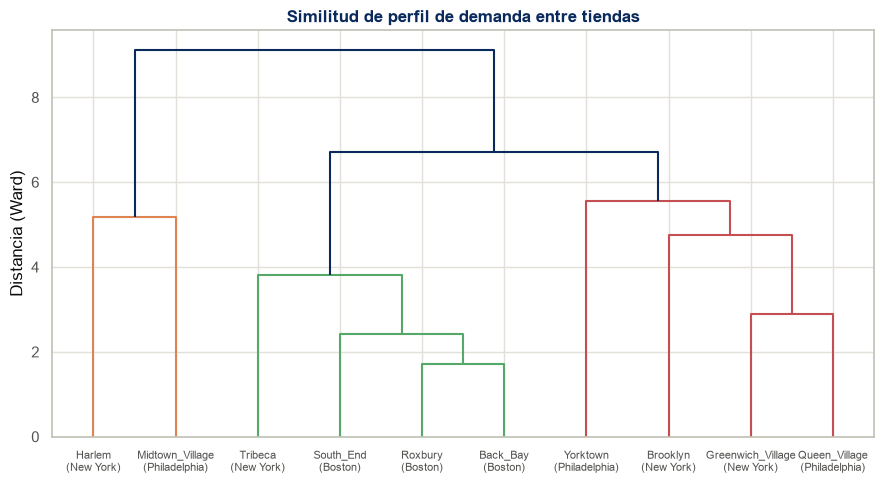

In [20]:
X_stores = StandardScaler().fit_transform(store_feat[STORE_FEAT_COLS].values)
Z = linkage(X_stores, method='ward')

fig, ax = plt.subplots(figsize=(9, 5))
labels_dendro = [f"{s}\n({r})" for s, r in zip(store_feat['store'], store_feat['region'])]
dendrogram(Z, labels=labels_dendro, ax=ax, color_threshold=0.7 * max(Z[:, 2]),
           above_threshold_color=DSMARKET_NAVY)
ax.set_title('Similitud de perfil de demanda entre tiendas', color=DSMARKET_NAVY, fontweight='bold')
ax.set_ylabel('Distancia (Ward)')
plt.xticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

### 5.4. ¿Cuántos grupos? Métricas para K=2, 3 y 4

Igual que con productos, miramos las tres métricas en vez de una sola, y comparamos jerárquico contra K-Means para confirmar que la agrupación no depende del algoritmo elegido.

In [21]:
store_results = []
for k in [2, 3, 4]:
    labels_h = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_stores)
    labels_km = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_stores)
    store_results.append({
        'k': k,
        'silhouette_jerarquico': silhouette_score(X_stores, labels_h),
        'silhouette_kmeans': silhouette_score(X_stores, labels_km),
        'davies_bouldin': davies_bouldin_score(X_stores, labels_h),
        'calinski_harabasz': calinski_harabasz_score(X_stores, labels_h),
        'ARI_jerarquico_vs_kmeans': adjusted_rand_score(labels_h, labels_km),
    })
    store_feat[f'cluster_k{k}'] = labels_h

pd.DataFrame(store_results).set_index('k').round(3)

,silhouette_jerarquico,silhouette_kmeans,davies_bouldin,calinski_harabasz,ARI_jerarquico_vs_kmeans
k,,,,,
2,0.308,0.308,1.049,4.245,1.0
3,0.201,0.201,1.209,4.016,1.0
4,0.208,0.208,0.922,3.926,1.0


### 5.5. Interpretación — K=3

El silhouette más alto de los tres es K=2 (0.308: la separación más obvia), pero es poco informativo para una estrategia de expansión ("la tienda grande vs. todas las demás"). **K=3 es el más útil en términos de negocio** — silhouette 0.201, todavía razonable, y separa tres perfiles distintos en vez de un binario. El ARI jerárquico vs. K-Means es **1.0 en los tres valores de K**: las dos familias de algoritmos encuentran exactamente la misma partición, así que la agrupación no es un artefacto del método elegido.

In [22]:
resumen_grupos = store_feat[['store', 'region', 'cluster_k3', 'avg_daily',
                             'weekend_lift', 'dec_lift', 'price_index_pct']].sort_values('cluster_k3')
resumen_grupos.round(2)

,store,region,cluster_k3,avg_daily,weekend_lift,dec_lift,price_index_pct
store_code,,,,,,,
NYC_1,Greenwich_Village,New York,0,4024.16,1.42,0.95,0.36
NYC_4,Brooklyn,New York,0,2145.15,1.20,0.94,0.38
PHI_2,Yorktown,Philadelphia,0,3420.81,1.16,0.98,0.67
PHI_3,Queen_Village,Philadelphia,0,3360.05,1.29,0.96,0.32
NYC_2,Harlem,New York,1,2972.02,1.50,0.97,0.40
PHI_1,Midtown_Village,Philadelphia,1,2691.62,1.41,1.07,0.46
BOS_1,South_End,Boston,2,2924.88,1.33,0.95,-0.80
BOS_2,Roxbury,Boston,2,3771.24,1.32,0.95,-0.85
BOS_3,Back_Bay,Boston,2,3183.13,1.26,0.94,-0.55


**Hallazgo — el perfil de demanda NO respeta las fronteras de ciudad, y es un resultado accionable para la estrategia de expansión de Michelle:**

- **Grupo 2:** las 3 tiendas de Boston (South End, Roxbury, Back Bay) **+ Tribeca (NYC)**. La tienda de Tribeca — que en el EDA (sección 10.1) ya aparecía como la "rara" dentro de Nueva York por precio, con índice -0.39% cuando el resto de NY está en +0.36/+0.40% — también se agrupa con Boston por su perfil de demanda completo: mix de departamento, estacionalidad y volumen, no solo precio.
- **Grupo 1:** Harlem (NYC) + Midtown Village (Filadelfia) — dos tiendas de ciudades distintas con los `weekend_lift` más altos del conjunto (1.50 y 1.41) y, en el caso de Midtown Village, el único `dec_lift` por encima de 1 de las diez tiendas.
- **Grupo 0:** el resto — Greenwich Village y Brooklyn (NY), Yorktown y Queen Village (Filadelfia).

**Para Michelle (plan de expansión):** el mensaje central es que "ciudad" no es el mejor eje para pensar en qué se parece a qué tienda — el perfil de demanda cruza ciudades. Si se abre una tienda nueva, el punto de partida más útil no es copiar el perfil promedio de su ciudad, sino identificar a qué grupo de comportamiento se va a parecer (por tipo de barrio y zona, no por ciudad) y usar esas tiendas como referencia para surtido y previsión inicial.

### 5.6. ¿Qué tan estable es esto con solo 10 tiendas? Validación leave-one-out

Es la pregunta que hay que hacerse antes de llevarle a Michelle una recomendación de expansión: con 10 tiendas y 12 variables, ¿los grupos son estructura real o son ruido? La prueba: sacamos una tienda, volvemos a clusterizar con las 9 restantes, y miramos si cada **par** de tiendas que estaba junto sigue junto (y cada par separado sigue separado). Repetimos las 10 veces, una por cada tienda excluida.

In [23]:
lab_full = store_feat['cluster_k3'].values
nombres = store_feat['store'].values
regiones = store_feat['region'].values
n = len(store_feat)

pares_base = {(i, j): lab_full[i] == lab_full[j] for i, j in itertools.combinations(range(n), 2)}
coincidencias = {p: [] for p in pares_base}

for fuera in range(n):
    quedan = [i for i in range(n) if i != fuera]
    X_sub = StandardScaler().fit_transform(store_feat[STORE_FEAT_COLS].values[quedan])
    lab_sub = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_sub)
    mapa = {quedan[i]: lab_sub[i] for i in range(len(quedan))}
    for (i, j) in pares_base:
        if i in mapa and j in mapa:
            coincidencias[(i, j)].append((mapa[i] == mapa[j]) == pares_base[(i, j)])

estabilidad = {p: np.mean(v) for p, v in coincidencias.items()}
print(f"Estabilidad global: en el {np.mean(list(estabilidad.values())):.1%} de los casos, "
      f"cada par de tiendas mantiene su relación (juntas o separadas) al sacar una tienda del análisis.\n")

inestables = {p: v for p, v in estabilidad.items() if v < 1.0}
print(f"Pares que cambian en alguna de las 10 iteraciones ({len(inestables)} de {len(pares_base)}):")
for (i, j), v in sorted(inestables.items(), key=lambda x: x[1]):
    print(f"  {nombres[i]:<18s} <-> {nombres[j]:<18s}  coinciden el {v:.0%} de las veces")

print("\nPares del Grupo A (el hallazgo principal) — ¿se mantienen siempre juntos?")
grupo_a = [i for i in range(n) if lab_full[i] == lab_full[list(nombres).index('Tribeca')]]
for i, j in itertools.combinations(grupo_a, 2):
    print(f"  {nombres[i]:<18s} <-> {nombres[j]:<18s}  {estabilidad[(min(i,j), max(i,j))]:.0%}")

Estabilidad global: en el 94.4% de los casos, cada par de tiendas mantiene su relación (juntas o separadas) al sacar una tienda del análisis.

Pares que cambian en alguna de las 10 iteraciones (14 de 45):
  South_End          <-> Greenwich_Village   coinciden el 75% de las veces
  Roxbury            <-> Greenwich_Village   coinciden el 75% de las veces
  Back_Bay           <-> Greenwich_Village   coinciden el 75% de las veces
  Greenwich_Village  <-> Tribeca             coinciden el 75% de las veces
  Greenwich_Village  <-> Brooklyn            coinciden el 75% de las veces
  Greenwich_Village  <-> Yorktown            coinciden el 75% de las veces
  South_End          <-> Queen_Village       coinciden el 88% de las veces
  Roxbury            <-> Queen_Village       coinciden el 88% de las veces
  Back_Bay           <-> Queen_Village       coinciden el 88% de las veces
  Tribeca            <-> Queen_Village       coinciden el 88% de las veces
  Brooklyn           <-> Midtown_Village     

**Hallazgo — el resultado principal es sólido, y la parte que se mueve es justamente la que menos nos importa:**

La estabilidad global es **94.4%**: en promedio, cada par de tiendas mantiene su relación (juntas o separadas) al re-clusterizar sin una de ellas. Pero el detalle importa más que el promedio:

- **Los seis pares del Grupo 2 (las tres de Boston + Tribeca) se mantienen juntos el 100% de las veces**, en las diez iteraciones. El hallazgo que le vamos a llevar a Michelle — que Tribeca se comporta como una tienda de Boston — no depende de ninguna otra tienda en particular ni de un accidente de la muestra.
- Lo mismo pasa con Harlem ↔ Midtown Village: nunca se separan.
- Los 14 pares que sí se mueven involucran casi todos a **Greenwich Village** (6 pares, coinciden solo el 75% de las veces) y al grupo residual. Son las tiendas "del medio", sin perfil marcado, que según qué otras estén presentes caen de un lado o del otro.

Dicho de otro modo: lo estable es la parte interesante (las dos agrupaciones con identidad propia) y lo que se mueve es la bolsa residual. **Así lo vamos a reportar en la memoria:** con 10 tiendas no afirmamos que existan exactamente tres grupos naturales, sino que hay **dos agrupaciones robustas que cruzan fronteras de ciudad** y un resto sin perfil diferenciado. Es una conclusión más chica que "hay 3 clusters", pero es la que aguanta la evidencia.

### 5.7. ¿Cambia algo si ponderamos el índice de precio por volumen?

La otra decisión metodológica que puede mover el resultado: el índice de precio simple trata igual a un producto que vende 50.000 unidades y a uno que vende 500. Rehacemos el clustering con la variante ponderada por volumen y comparamos las dos particiones con ARI.

In [24]:
STORE_FEAT_COLS_PONDERADO = (['log_avg_daily', 'cv_daily', 'weekend_lift', 'dec_lift', 'price_index_ponderado']
                             + DEPT_COLS)
X_stores_pond = StandardScaler().fit_transform(store_feat[STORE_FEAT_COLS_PONDERADO].values)
lab_pond = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_stores_pond)

comp_precio = pd.DataFrame({
    'tienda': store_feat['store'].values, 'ciudad': store_feat['region'].values,
    'indice_simple_pct': store_feat['price_index_pct'].round(2).values,
    'indice_ponderado_pct': store_feat['price_index_ponderado'].round(2).values,
    'grupo_con_simple': lab_full, 'grupo_con_ponderado': lab_pond,
}).sort_values('indice_simple_pct')

print(f"ARI entre las dos particiones: {adjusted_rand_score(lab_full, lab_pond):.3f}")
print(f"Silhouette con índice simple: {silhouette_score(X_stores, lab_full):.3f} | "
      f"con índice ponderado: {silhouette_score(X_stores_pond, lab_pond):.3f}")
comp_precio

ARI entre las dos particiones: 1.000
Silhouette con índice simple: 0.201 | con índice ponderado: 0.194


,tienda,ciudad,indice_simple_pct,indice_ponderado_pct,grupo_con_simple,grupo_con_ponderado
1,Roxbury,Boston,-0.85,-1.19,2,2
0,South_End,Boston,-0.80,-1.22,2,2
2,Back_Bay,Boston,-0.55,-0.75,2,2
5,Tribeca,New York,-0.39,-0.23,2,2
9,Queen_Village,Philadelphia,0.32,0.25,0,0
3,Greenwich_Village,New York,0.36,0.64,0,0
6,Brooklyn,New York,0.38,0.59,0,0
4,Harlem,New York,0.40,0.37,1,1
7,Midtown_Village,Philadelphia,0.46,0.39,1,1
8,Yorktown,Philadelphia,0.67,0.61,0,0


**Hallazgo — la conclusión no depende de esta decisión metodológica:**

El **ARI entre ambas particiones es 1.000**: los tres grupos quedan exactamente iguales usando el índice simple o el ponderado por volumen. El silhouette apenas se mueve (0.201 contra 0.194). Lo único que cambia es la magnitud del índice, no el orden ni la agrupación: al ponderar por volumen el descuento de Boston se acentúa (South End pasa de -0.80% a -1.22%, Roxbury de -0.85% a -1.19%) y Tribeca se modera un poco (-0.39% a -0.23%), pero Boston sigue siendo la ciudad sistemáticamente más barata, Filadelfia la más cara, y Tribeca la excepción dentro de Nueva York.

Es una buena noticia para la memoria: podemos reportar el índice simple, que es más fácil de explicar, dejando documentado que la versión ponderada — más fiel a lo que paga un cliente real — no cambia ninguna conclusión.

## 6. Estado de la Tarea 2 (Clustering) y próximos pasos

Cubrimos las dos preguntas de Joelle y sumamos las validaciones necesarias para defender el trabajo:

| Pedido | Resultado |
|---|---|
| Agrupar productos por comportamiento (K=5/10/20) | **K=5** como segmentación principal (5 arquetipos interpretados) y **K=10** como segmentación de campaña (2 micro-segmentos con fecha propia). K=20 descartado: deja grupos de 1 producto. |
| ¿Sirve el mismo enfoque para tiendas? | Sí, con jerárquico en vez de K-Means por el tamaño de la muestra. **2 agrupaciones robustas que cruzan ciudades** + un resto sin perfil marcado. |
| Elección de algoritmo | K-Means supera a GMM en las tres métricas y da perfiles más interpretables (sección 4.3). Jerárquico y K-Means coinciden al 100% en tiendas. |
| Robustez | Leave-one-out en tiendas: 94.4% global, 100% en el grupo Boston+Tribeca (sección 5.6). El índice de precio ponderado no cambia nada (sección 5.7). |

**Notas para las tareas siguientes** (las dejo acá anotadas para no perderlas cuando cambiemos de notebook):

**→ Tarea 3 (predicción de ventas).** Dos cosas de este notebook se usan directamente allá:
1. Paul preguntó si sumar predicciones tienda-producto para llegar a agregados por ciudad sigue siendo válido. La evidencia de la sección 5.5 sugiere que **agregar por grupo de comportamiento puede ser más consistente que agregar por ciudad geográfica** — Tribeca se parece más a Boston que a sus vecinas de Nueva York. Vale la pena medir el error de ambas agregaciones y llevarle la comparación con números.
2. Los grupos de producto son candidatos naturales a **variable de entrada del modelo** (un producto de la "cola larga" con 66% de días sin venta necesita otro tratamiento que uno del "núcleo estable"), y el Grupo 9 / `SUPERMARKET_3_069` son el caso de prueba obvio para verificar que el modelo capta la estacionalidad de fin de año.

**→ Tarea 4 (abastecimiento).** Los cinco arquetipos mapean casi uno a uno con políticas de reposición distintas: el "núcleo estable" (baja volatilidad, sin días sin venta) admite reposición automática con stock de seguridad chico; la "cola larga" (66% de días sin venta, alta volatilidad) necesita el criterio opuesto o directamente una política de pedido bajo demanda; el "premium" combina volumen bajo con capital inmovilizado alto por unidad; y los segmentos estacionales (Grupo 9 de K=10) requieren una política con calendario, no una regla anual fija. Esta es la conexión que conviene desarrollar en el documento de propuesta.

**Pendiente de decisión con el equipo:**
1. **Validación con Joelle:** los nombres de los cinco arquetipos son una primera lectura nuestra. Antes de llevarlos a la memoria como definitivos conviene chequear que tengan sentido para cómo se arman las campañas hoy.
2. **Traducción a la memoria:** falta definir si la interpretación de negocio (secciones 4.5, 4.6 y 5.5) va tal cual o si se resume, y si las comparaciones metodológicas (GMM, leave-one-out, índice ponderado) van al cuerpo principal o a un anexo.